# Lab 4 – Character-Level Language Model Using RNN

**Objective:** Build a character-level language model using a Recurrent Neural Network (RNN). The model learns from a text corpus and predicts the next character from a sequence of 40 preceding characters.

**Prediction task:** 40 input characters → predict the 41st character.



## Import required libraries

In [14]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Input
from tensorflow.keras.callbacks import EarlyStopping

# Improve reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## Question 1. Load text and build character-to-index and index-to-character mappings.

The corpus is loaded as UTF-8 text. The file-size check enforces the assignment's 500 KB limit.

In [15]:
# Load the dataset
file_path = "input.txt"

with open(file_path, "r", encoding="utf-8") as file:
    text = file.read()

file_size = os.path.getsize(file_path)

print("Text loaded successfully!")
print("Dataset file:", file_path)
print("File size:", file_size, "bytes")
print("Total characters:", len(text))

# Validate dataset size (maximum 50 KB)
if file_size > 50 * 1024:
    raise ValueError("Text file must be 50 KB or smaller.")

# Define sequence length
sequence_length = 40

if len(text) <= sequence_length:
    raise ValueError(
        f"Text must contain more than {sequence_length} characters."
    )

# Build character vocabulary and mappings
chars = sorted(set(text))
vocab_size = len(chars)

char_to_idx = {char: idx for idx, char in enumerate(chars)}
idx_to_char = {idx: char for idx, char in enumerate(chars)}

print("\nCharacter vocabulary:")
print(chars)

print("Vocabulary size:", vocab_size)

print("\nCharacter-to-index mapping:")
print(char_to_idx)

print("\nIndex-to-character mapping:")
print(idx_to_char)

Text loaded successfully!
Dataset file: input.txt
File size: 8517 bytes
Total characters: 8489

Character vocabulary:
['\n', ' ', '!', '"', "'", '(', ')', ',', '-', '.', ':', ';', '?', 'A', 'B', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'R', 'S', 'T', 'W', 'Z', '_', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']
Vocabulary size: 59

Character-to-index mapping:
{'\n': 0, ' ': 1, '!': 2, '"': 3, "'": 4, '(': 5, ')': 6, ',': 7, '-': 8, '.': 9, ':': 10, ';': 11, '?': 12, 'A': 13, 'B': 14, 'D': 15, 'E': 16, 'F': 17, 'G': 18, 'H': 19, 'I': 20, 'K': 21, 'L': 22, 'M': 23, 'N': 24, 'O': 25, 'P': 26, 'R': 27, 'S': 28, 'T': 29, 'W': 30, 'Z': 31, '_': 32, 'a': 33, 'b': 34, 'c': 35, 'd': 36, 'e': 37, 'f': 38, 'g': 39, 'h': 40, 'i': 41, 'j': 42, 'k': 43, 'l': 44, 'm': 45, 'n': 46, 'o': 47, 'p': 48, 'q': 49, 'r': 50, 's': 51, 't': 52, 'u': 53, 'v': 54, 'w': 55, 'x': 56, 'y': 57, 'z': 58}

Index-to-cha

## Question 2. Create input sequences of length 40 characters to predict the 41st character.

In [16]:
encoded_text = [char_to_idx[char] for char in text]

print("Sequence length:", sequence_length)
print("\nFirst 50 encoded characters:")
print(encoded_text[:50])
print("\nCorresponding original text:")
print(text[:50])

Sequence length: 40

First 50 encoded characters:
[13, 44, 41, 35, 37, 1, 55, 33, 51, 1, 34, 37, 39, 41, 46, 46, 41, 46, 39, 1, 52, 47, 1, 39, 37, 52, 1, 54, 37, 50, 57, 1, 52, 41, 50, 37, 36, 1, 47, 38, 1, 51, 41, 52, 52, 41, 46, 39, 1, 34]

Corresponding original text:
Alice was beginning to get very tired of sitting b


## Question 3. Create training, validation and testing sequences.
70% training, 15% validation and 15% testing segments.

In [17]:
total_length = len(encoded_text)
train_end = int(0.70 * total_length)
val_end = int(0.85 * total_length)

train_text = encoded_text[:train_end]
val_text = encoded_text[train_end + sequence_length:val_end]
test_text = encoded_text[val_end + sequence_length:]


def create_sequences(data, sequence_length):
    """Create fixed-length input windows and their next-character targets."""
    X, y = [], []
    for i in range(sequence_length, len(data)):
        X.append(data[i - sequence_length:i])
        y.append(data[i])
    return np.asarray(X, dtype=np.int32), np.asarray(y, dtype=np.int32)


X_train, y_train = create_sequences(train_text, sequence_length)
X_val, y_val = create_sequences(val_text, sequence_length)
X_test, y_test = create_sequences(test_text, sequence_length)

if min(len(X_train), len(X_val), len(X_test)) == 0:
    raise ValueError("The dataset is too small to create all three data splits.")

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))
print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)

Training samples: 5902
Validation samples: 1193
Testing samples: 1194
Training shape: (5902, 40)
Validation shape: (1193, 40)
Testing shape: (1194, 40)


## One-hot encoding

In [18]:
X_train_onehot = tf.one_hot(X_train, depth=vocab_size, dtype=tf.float32).numpy()
X_val_onehot = tf.one_hot(X_val, depth=vocab_size, dtype=tf.float32).numpy()
X_test_onehot = tf.one_hot(X_test, depth=vocab_size, dtype=tf.float32).numpy()

print("Training one-hot shape:", X_train_onehot.shape)
print("Validation one-hot shape:", X_val_onehot.shape)
print("Testing one-hot shape:", X_test_onehot.shape)

Training one-hot shape: (5902, 40, 59)
Validation one-hot shape: (1193, 40, 59)
Testing one-hot shape: (1194, 40, 59)


## Question 4. Build the RNN model.

In [19]:
model = Sequential([
    Input(shape=(sequence_length, vocab_size)),
    SimpleRNN(256, activation="tanh", return_sequences=True),
    SimpleRNN(256, activation="tanh"),
    Dense(vocab_size, activation="softmax")
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_2 (SimpleRNN)        │ (None, 40, 256)        │        80,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_3 (SimpleRNN)        │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 59)             │        15,163 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 227,387 (888.23 KB)

 Trainable params: 227,387 (888.23 KB)

 Non-trainable params: 0 (0.00 B)

## Question 5. Compile and train the model

### Compile the model

In [20]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


### Train the model

In [21]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

history = model.fit(
    X_train_onehot,
    y_train,
    epochs=30,
    batch_size=64,
    validation_data=(X_val_onehot, y_val),
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/30
93/93 ━━━━━━━━━━━━━━━━━━━━ 5s 46ms/step - accuracy: 0.1879 - loss: 3.1106 - val_accuracy: 0.2112 - val_loss: 2.9150
Epoch 2/30
93/93 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step - accuracy: 0.2528 - loss: 2.8314 - val_accuracy: 0.2842 - val_loss: 2.6615
Epoch 3/30
93/93 ━━━━━━━━━━━━━━━━━━━━ 5s 49ms/step - accuracy: 0.3038 - loss: 2.5929 - val_accuracy: 0.3261 - val_loss: 2.4875
Epoch 4/30
93/93 ━━━━━━━━━━━━━━━━━━━━ 5s 49ms/step - accuracy: 0.3480 - loss: 2.3865 - val_accuracy: 0.3386 - val_loss: 2.4222
Epoch 5/30
93/93 ━━━━━━━━━━━━━━━━━━━━ 5s 49ms/step - accuracy: 0.3873 - loss: 2.2275 - val_accuracy: 0.3328 - val_loss: 2.3529
Epoch 6/30
93/93 ━━━━━━━━━━━━━━━━━━━━ 5s 49ms/step - accuracy: 0.4124 - loss: 2.0749 - val_accuracy: 0.3386 - val_loss: 2.3386
Epoch 7/30
93/93 ━━━━━━━━━━━━━━━━━━━━ 5s 49ms/step - accuracy: 0.4443 - loss: 1.9319 - val_accuracy: 0.3604 - val_loss: 2.3031
Epoch 8/30
93/93 ━━━━━━━━━━━━━━━━━━━━ 5s 49ms/step - accuracy: 0.4792 - loss: 1.7926 - val_accuracy: 0.3655 - v

### Visualise training performance

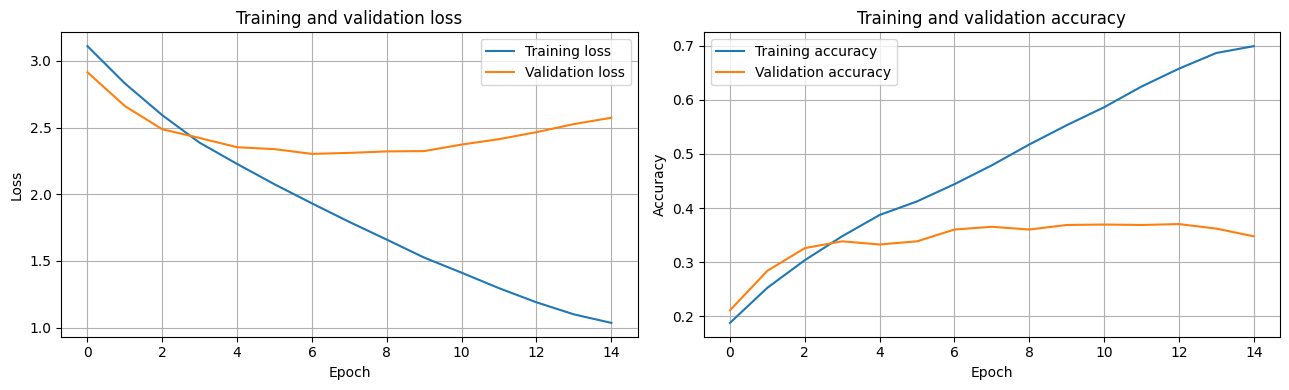

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history.history["loss"], label="Training loss")
axes[0].plot(history.history["val_loss"], label="Validation loss")
axes[0].set_title("Training and validation loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history.history["accuracy"], label="Training accuracy")
axes[1].plot(history.history["val_accuracy"], label="Validation accuracy")
axes[1].set_title("Training and validation accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

* Training vs. Validation Loss: Training loss steadily decreases from approximately 3.1 to 1.0. Validation loss decreases initially, reaches its lowest point around epoch 6, and then gradually increases. This indicates that the model begins to overfit the training data.



* Training vs. Validation Accuracy: Training accuracy increases consistently to 70%, while validation accuracy remains around 34–37% and slightly declines towards the end. This indicates that the model learns the training data better but struggles to generalise to unseen data.

## Evaluate the trained model

In [23]:
test_loss, test_accuracy = model.evaluate(
    X_test_onehot,
    y_test,
    verbose=0
)

# Majority-character baseline for context
majority_class = np.bincount(
    y_train, minlength=vocab_size
).argmax()
baseline_accuracy = np.mean(y_test == majority_class)

print("Model evaluation")
print("------------------------------")
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")
print("Majority character:", idx_to_char[majority_class])
print(f"Baseline accuracy: {baseline_accuracy * 100:.2f}%")

Model evaluation
------------------------------
Test loss: 2.6201
Test accuracy: 29.73%
Majority character:  
Baseline accuracy: 17.76%


## Question 6. Write the text-generation function.

In [24]:
def generate_text(seed_text, num_chars=200, temperature=0.8):
    if len(seed_text) < sequence_length:
        raise ValueError(
            f"Seed text must contain at least {sequence_length} characters."
        )
    if temperature <= 0:
        raise ValueError("Temperature must be greater than zero.")
    if num_chars < 0:
        raise ValueError("num_chars cannot be negative.")
    if any(char not in char_to_idx for char in seed_text):
        raise ValueError("Seed text contains characters not in the vocabulary.")

    generated_text = seed_text

    for _ in range(num_chars):
        # Use the most recent context window
        input_text = generated_text[-sequence_length:]
        input_sequence = np.array(
            [[char_to_idx[char] for char in input_text]],
            dtype=np.int32
        )
        input_onehot = tf.one_hot(
            input_sequence,
            depth=vocab_size,
            dtype=tf.float32
        )

        predictions = model.predict(input_onehot, verbose=0)[0]

        # Apply temperature and convert scores to probabilities
        scaled_logits = np.log(np.maximum(predictions, 1e-10)) / temperature
        probabilities = np.exp(scaled_logits - np.max(scaled_logits))
        probabilities /= probabilities.sum()

        predicted_id = np.random.choice(vocab_size, p=probabilities)
        generated_text += idx_to_char[int(predicted_id)]

    return generated_text

## Question 7. Generate new text and validate

In [25]:
seed_text = text[:sequence_length]

generated_output = generate_text(
    seed_text,
    num_chars=200,
    temperature=0.8
)

print("Original seed text:")
print(seed_text)
print("\nGenerated text:")
print(generated_output)
print("\nText generation completed successfully!")

Original seed text:
Alice was beginning to get very tired of

Generated text:
Alice was beginning to get very tired of word at taven- heon as sollige awts, io nat she houther abeang to sayle wits betling town therell abithing hambut that wor down the frelldpt' he we tod suderen ton the mice the warbrsing on uuleerrri

Text generation completed successfully!


## Self-learning: Effect of temperature on text generation

In [26]:
temperatures = [0.2, 0.5, 0.8, 1.2]
seed_text = text[:sequence_length]

for temp in temperatures:
    print(f"\nTemperature: {temp}")
    print("-" * 50)
    print(generate_text(seed_text, num_chars=150, temperature=temp))


Temperature: 0.2
--------------------------------------------------
Alice was beginning to get very tired of she was down the found wous the sall watd and whed she was dother wound to sithe sall was soucd ood the watk oo the wast was tound the was down wert 

Temperature: 0.5
--------------------------------------------------
Alice was beginning to get very tired of wind at the wort maca wath the tound utothenge to semere
we wound houseat thine wo chath mulent that wouk the sout so tat wougethe sime at she was to

Temperature: 0.8
--------------------------------------------------
Alice was beginning to get very tired of then'ngrelinn 'hite hownd matsyy troll!ne the semerell, 'oudan nopeoreed-to tomevery I be there fice fae inde to so: wolleme sid wotheng of limened w

Temperature: 1.2
--------------------------------------------------
Alice was beginning to get very tired of sinf eithey abamad. tOlly iutimeMuphWoe lleAl-cach macxit ting! tow sud wfs:e-Dcrkhes!e fhere wcethatbe, ious 

## Conclusion

- Achieved a test accuracy of 29.73%, outperforming the majority-character baseline of 17.76%.
- EarlyStopping prevents unnecessary training by stopping when validation loss no longer improves.
- The generated text captured some character patterns from the input, although it was not always grammatically meaningful due to the limitations of the model and dataset.